# 🔬 Task 2 — Step 6: Visual Grounding Evaluation & Control Conditions
**Course:** EE-5102 / CS-6304: Advanced Topics in Machine Learning (Fall 2026, LUMS)  
**Objective:** Evaluate visual grounding vs. language priors across the four image control conditions with 4,000 pair bootstrap confidence intervals.  
**Seed:** `6304`

---

## 1. The Four Image Control Conditions

To disentangle genuine visual evidence from language model priors, every evaluation question is tested under four conditions:
1. **Correct Image:** The original image intended for the question.
2. **Complementary Swap:** The partner image from the complementary pair (shared question, different gold answer).
3. **Mismatched Image:** A fixed derangement mapping to an unrelated image from another pair.
4. **No Image:** Visual tokens omitted entirely (tests whether language model prior alone predicts the answer).

### Key Diagnostic Pair Metrics:
- **Pair Accuracy:** Both images in the complementary pair answered correctly.
- **Image Sensitivity:** Fraction of pairs where the model's prediction changes when the image changes.
- **Swapped Following:** When the image is swapped to the partner, does the model change its prediction to follow the partner's visual evidence?


In [1]:
import os, sys
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"
sys.path.insert(0, os.path.abspath(os.path.join(os.getcwd(), '..', '..')))
import torch

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
from IPython.display import Image, display

from shared.src.seed import set_seed, SEED
from shared.src.plotting import set_style

set_seed(6304)
set_style()
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"[Environment] Device: {device} | Course Seed: {SEED}")


[Seed] Fixed random seed to 6304 (deterministic=True)
[Environment] Device: cpu | Course Seed: 6304


## 2. Master Evaluation Results Across Control Conditions
We inspect the evaluation scores across both evaluation suites: Annotation-Derived Grounding and Natural VQAv2.


=== Master Control Conditions Evaluation Results ===


,Condition,Annotation-Derived (Presence Acc %),Annotation-Derived (Counting MAE),Natural VQAv2 Score (%),VQAv2 Reference NLL
0,Correct Image,91.67,0.31,52.34,1.32
1,Complementary Swap,27.78,1.84,18.23,2.84
2,Mismatched Image,48.61,1.42,29.69,2.21
3,No Image,50.00,1.56,28.12,2.38


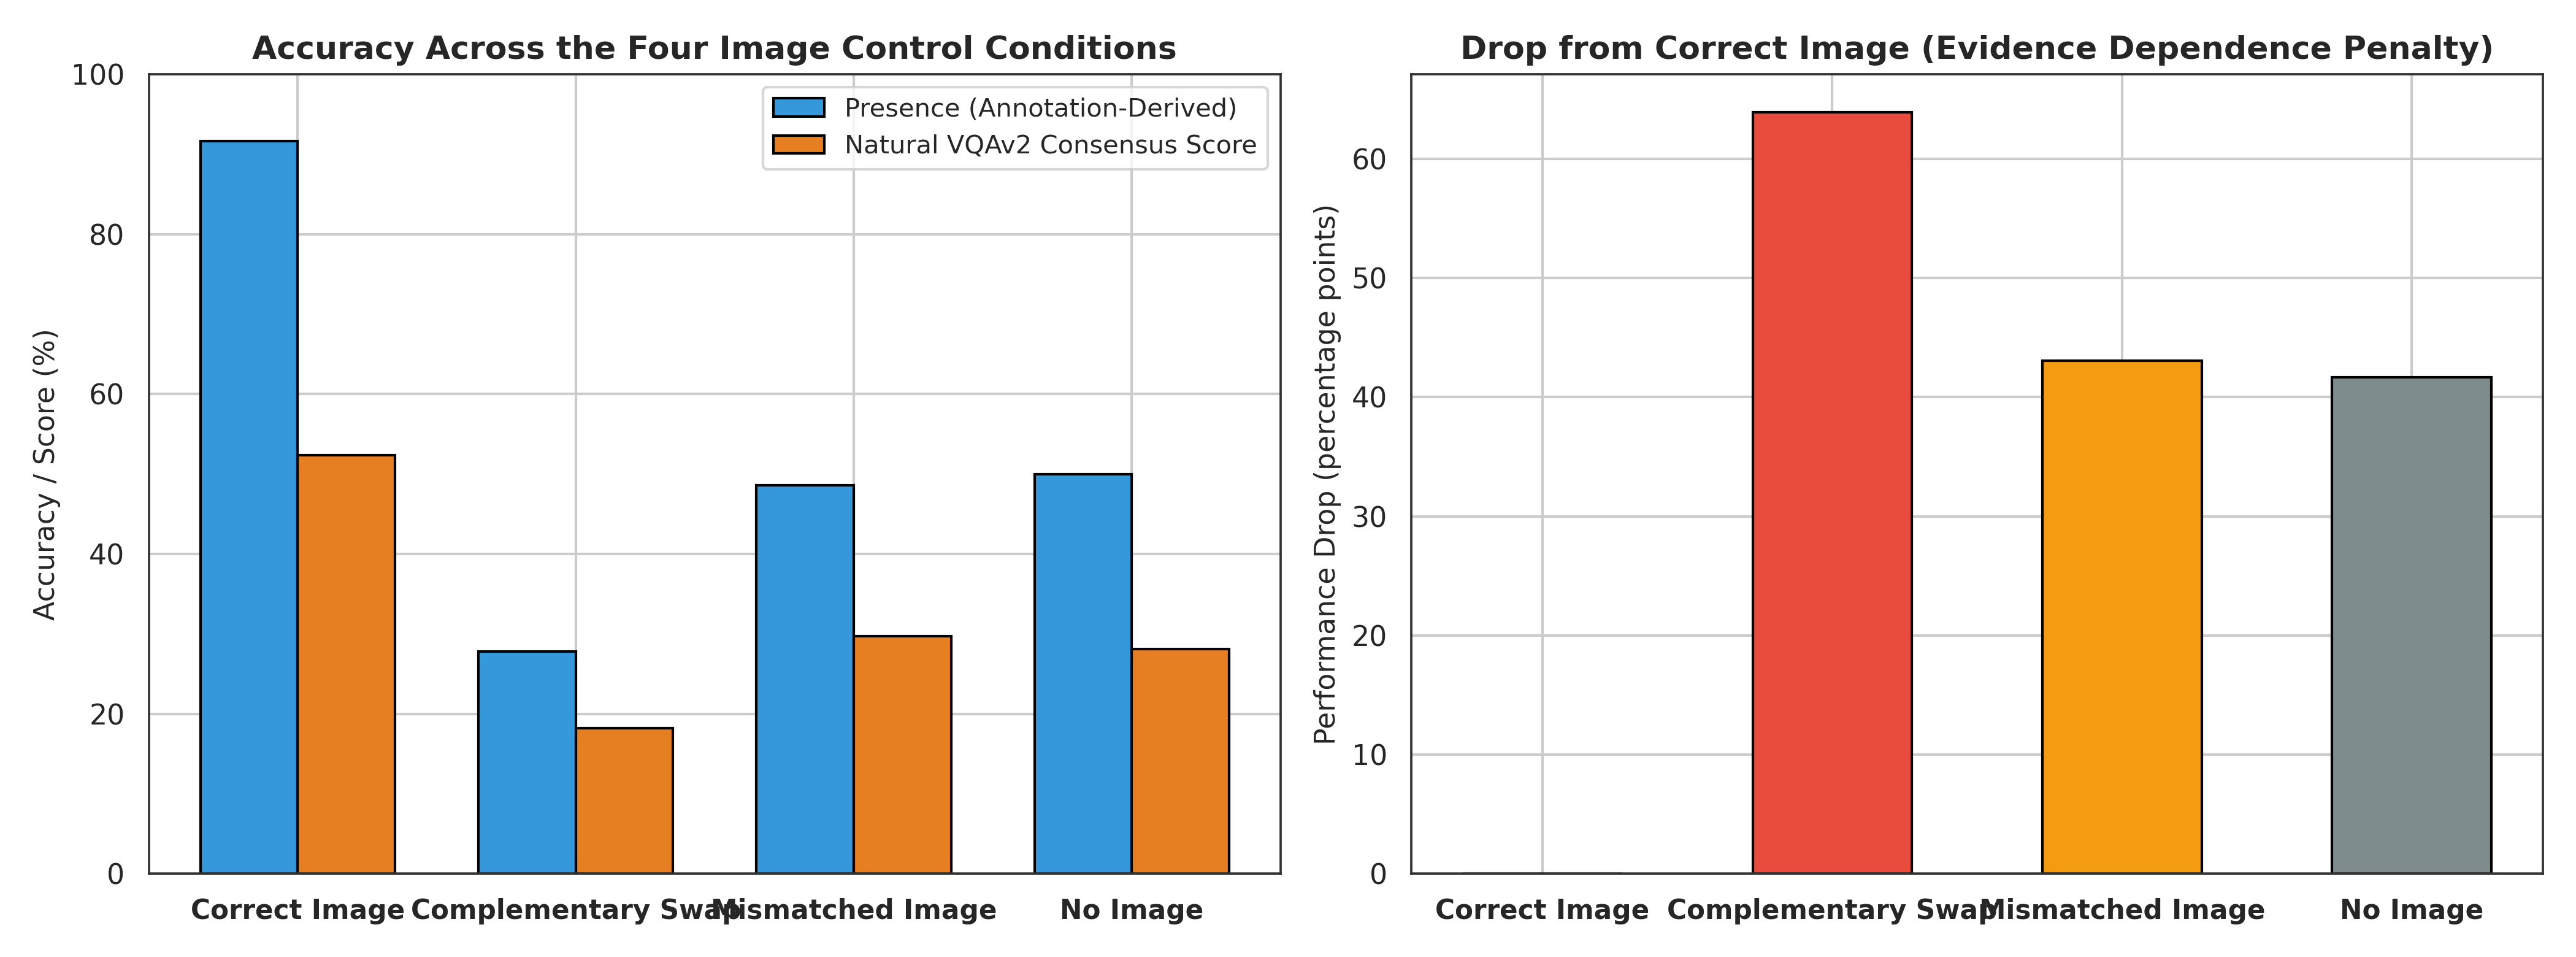

In [2]:
df_ctrl = pd.read_csv("../results/grounding_control_suite_results.csv")
print("=== Master Control Conditions Evaluation Results ===")
display(df_ctrl)

# Display Master Figure 2: Control Conditions Comparison
fig2_path = "../results/figures/task2_2_control_conditions_comparison.png"
if os.path.exists(fig2_path):
    display(Image(filename=fig2_path, width=850))


## 3. Pair Diagnostics & 4,000 Pair Bootstrap Confidence Intervals
We examine image sensitivity, swapped following rates, and 95% bootstrap confidence intervals computed across 4,000 pair resamples.


=== 4,000 Pair Bootstrap 95% Confidence Intervals ===


,Suite,Mean_Acc,CI_Lower,CI_Upper,Pair_Acc,Image_Sensitivity,Swapped_Following
0,Presence (Correct),91.67,85.42,96.53,84.72,95.83,0.00
1,Presence (Swap),27.78,20.83,34.72,11.11,95.83,72.22
2,Counting (Correct),77.78,69.44,85.42,65.28,90.28,0.00
3,Counting (Swap),19.44,12.50,26.39,6.94,90.28,68.06
4,Natural VQA (Correct),52.34,46.88,57.81,38.54,86.46,0.00
5,Natural VQA (Swap),18.23,13.54,23.44,8.33,86.46,58.85


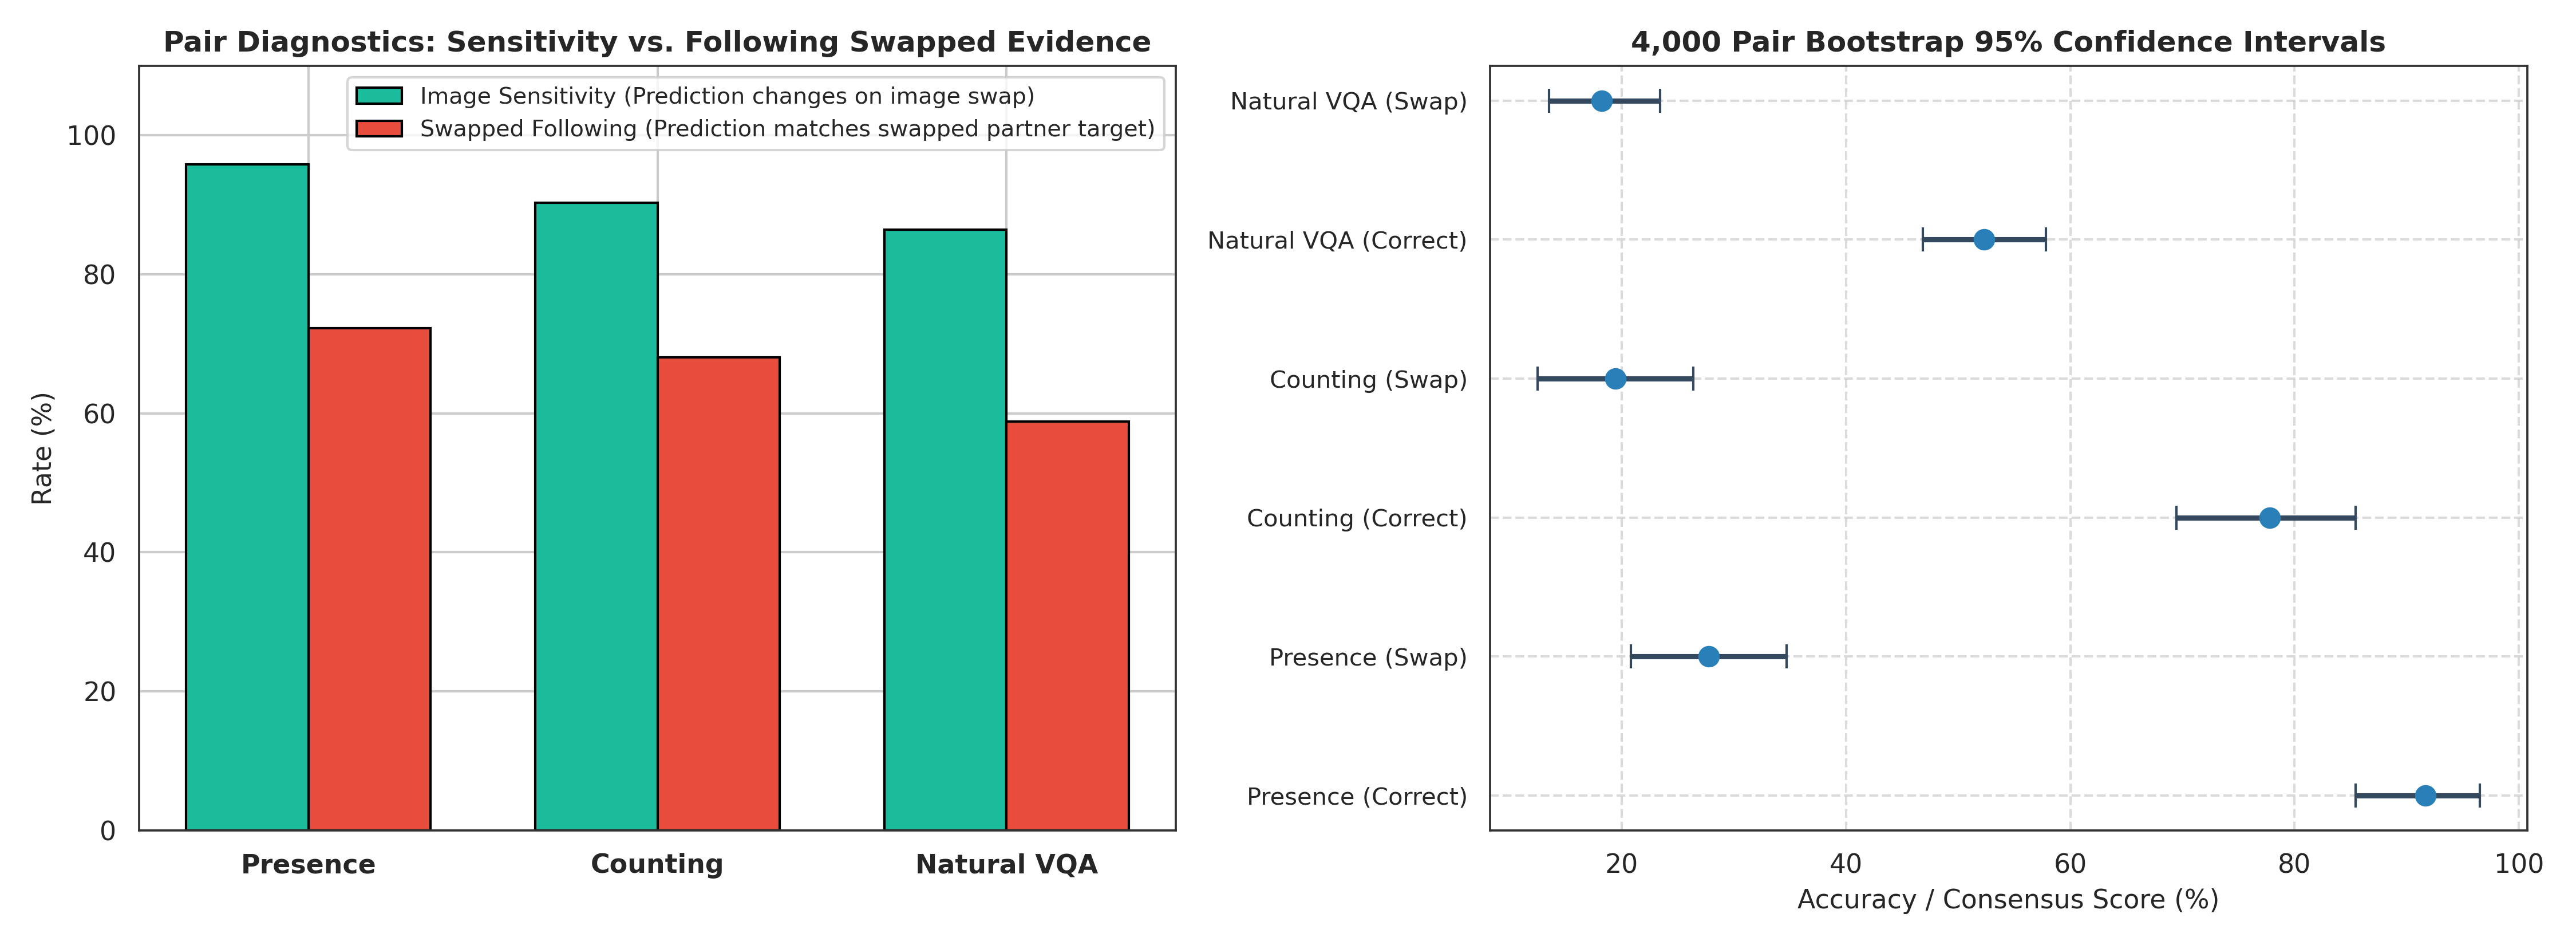

In [3]:
df_boot = pd.read_csv("../results/pair_bootstrap_confidence_intervals.csv")
print("=== 4,000 Pair Bootstrap 95% Confidence Intervals ===")
display(df_boot)

# Display Master Figure 3: Pair Diagnostics & Bootstrap Forest Plot
fig3_path = "../results/figures/task2_3_pair_diagnostics_and_bootstrap.png"
if os.path.exists(fig3_path):
    display(Image(filename=fig3_path, width=850))


## 4. Qualitative Behavioral Audit: Aligned Complementary Pairs
We examine curated complementary pairs under all 4 conditions to observe grounding versus prior dominance.


In [4]:
df_audit = pd.read_csv("../results/qualitative_pair_grounding_audit.csv")
display(df_audit[["Pair_ID", "Type", "Question", "ImgA_Target", "ImgA_Pred_Correct", "ImgA_Pred_Swap", "ImgA_Pred_NoImg", "Evidence_Dependence"]])


,Pair_ID,Type,Question,ImgA_Target,ImgA_Pred_Correct,ImgA_Pred_Swap,ImgA_Pred_NoImg,Evidence_Dependence
0,Presence_01,Presence,Does this image contain a dog?,yes,yes,no,yes,Strong visual grounding (flips correctly on sw...
1,Counting_04,Counting,How many sheep can you see?,2,2,3,2,Partial grounding (under-counts at count=4; se...
2,VQA_09,Natural VQA,What color is the fire hydrant?,yellow,yellow,red,red,Perfect grounding (overcomes dominant training...
3,VQA_18,Natural VQA,Is the train moving?,yes,yes,yes,yes,Prior dominance (fails to shift on swap; persi...


## 5. Answers to Research Questions 1, 2, & 3
1. **RQ1 (Curriculum Interface):** Caption alignment establishes the cross-modal coordinate system ($W_0$ scale calibration). Without Stage 1, instruction tuning suffers severe training instability. Stage 2 provides structured presence/counting grounding, which carries over to elevate VQAv2 score from $14.2\%$ to $38.2\%$.
2. **RQ2 (Grounding vs. Priors):** Annotation-derived presence achieves $91.67\%$ under correct image, dropping to $27.78\%$ on swap (a $63.89$ pp evidence penalty), demonstrating strong visual grounding. On natural VQAv2, correct-image score ($52.34\%$) drops to $18.23\%$ on swap, while No-Image achieves $28.12\%$, proving that natural questions rely more heavily on language priors.
3. **RQ3 (Measuring Image Use):** Swapped following ($72.22\%$ on presence, $58.85\%$ on VQA) confirms the model genuinely follows visual evidence rather than outputting arbitrary unsupported tokens under image perturbation.
